# Assignment 6: Image Smoothing

Smooth an input image using:

1. Averaging filter (unweighted)
2. Weighted filter given by $h(x,y) = \max(|x|, |y|)$
3. Gaussian filter

The filter size, the sigma of the Gaussian filter and the padding method are entered by the user.

**Requirements:** `pip install numpy matplotlib opencv-python scikit-image`

## Setup

To use your own image, set `INPUT_PATH`, for example `INPUT_PATH = "input.jpg"`. If it is left as `None`, a sample image from scikit-image is used.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from skimage import data

INPUT_PATH = None

if INPUT_PATH is None:
    image = data.camera()
else:
    image = cv2.imread(INPUT_PATH, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {INPUT_PATH}")

print("Image shape:", image.shape)

Image shape: (512, 512)


## User input

Run the next cell and answer each prompt. Press Enter to accept the default shown in brackets.

| Padding method | Border values come from |
|---|---|
| `zero` | Zeros |
| `replicate` | The nearest edge pixel |
| `symmetric` | A mirror image of the border |
| `circular` | The opposite side of the image |

In [2]:
PADDING_MODES = {
    "zero": "constant",
    "replicate": "edge",
    "symmetric": "symmetric",
    "circular": "wrap",
}


def ask_filter_size(default=5):
    while True:
        text = input(f"Filter size, odd and at least 3 [{default}]: ").strip()
        if not text:
            return default
        if text.isdigit() and int(text) >= 3 and int(text) % 2 == 1:
            return int(text)
        print("Please enter an odd whole number that is at least 3.")


def ask_sigma(default=1.0):
    while True:
        text = input(f"Sigma for the Gaussian filter [{default}]: ").strip()
        if not text:
            return default
        try:
            if float(text) > 0:
                return float(text)
        except ValueError:
            pass
        print("Please enter a number greater than 0.")


def ask_padding(default="replicate"):
    names = list(PADDING_MODES)
    menu = ", ".join(f"{i + 1}={name}" for i, name in enumerate(names))
    while True:
        text = input(f"Padding method ({menu}) [{default}]: ").strip().lower()
        if not text:
            return default
        if text in names:
            return text
        if text.isdigit() and 1 <= int(text) <= len(names):
            return names[int(text) - 1]
        print("Please choose one of the listed padding methods.")


filter_size = ask_filter_size()
sigma = ask_sigma()
padding = ask_padding()

print(f"\nUsing filter size = {filter_size}, sigma = {sigma}, padding = {padding}")

Filter size, odd and at least 3 [5]: 
Sigma for the Gaussian filter [1.0]: 
Padding method (1=zero, 2=replicate, 3=symmetric, 4=circular) [replicate]: 

Using filter size = 5, sigma = 1.0, padding = replicate


## Filters

For a filter of size $n \times n$, the coordinates $x$ and $y$ run from $-a$ to $a$, where $a = (n-1)/2$. Each kernel is divided by the sum of its coefficients, so overall brightness is preserved.

**Averaging filter**

$$h(x,y) = \frac{1}{n^2}$$

**Weighted filter**

$$h(x,y) = \frac{\max(|x|,|y|)}{\sum_x \sum_y \max(|x|,|y|)}$$

The centre coefficient of this filter is 0 and the weights increase towards the edges, so a pixel's new value comes entirely from its neighbours.

**Gaussian filter**

$$h(x,y) = \frac{e^{-(x^2+y^2)/2\sigma^2}}{\sum_x \sum_y e^{-(x^2+y^2)/2\sigma^2}}$$

In [3]:
def kernel_coordinates(size):
    a = size // 2
    return np.mgrid[-a:a + 1, -a:a + 1]


def averaging_kernel(size):
    return np.ones((size, size)) / size**2


def weighted_kernel(size):
    x, y = kernel_coordinates(size)
    h = np.maximum(np.abs(x), np.abs(y)).astype(float)
    return h / h.sum()


def gaussian_kernel(size, sigma):
    x, y = kernel_coordinates(size)
    h = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return h / h.sum()


def apply_filter(img, kernel, padding):
    """Pad the image, then convolve it with the kernel."""
    a = kernel.shape[0] // 2
    padded = np.pad(img.astype(float), a, mode=PADDING_MODES[padding])
    windows = sliding_window_view(padded, kernel.shape)
    result = np.einsum("ijkl,kl->ij", windows, kernel[::-1, ::-1])
    return np.clip(np.round(result), 0, 255).astype(np.uint8)

## Kernels

In [4]:
kernels = {
    "Averaging filter": averaging_kernel(filter_size),
    "Weighted filter": weighted_kernel(filter_size),
    "Gaussian filter": gaussian_kernel(filter_size, sigma),
}

np.set_printoptions(precision=4, suppress=True, linewidth=120)
for name, kernel in kernels.items():
    print(f"{name} (sum = {kernel.sum():.4f}):\n{kernel}\n")

Averaging filter (sum = 1.0000):
[[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]

Weighted filter (sum = 1.0000):
[[0.05  0.05  0.05  0.05  0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.025 0.    0.025 0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.05  0.05  0.05  0.05 ]]

Gaussian filter (sum = 1.0000):
[[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]



## Results

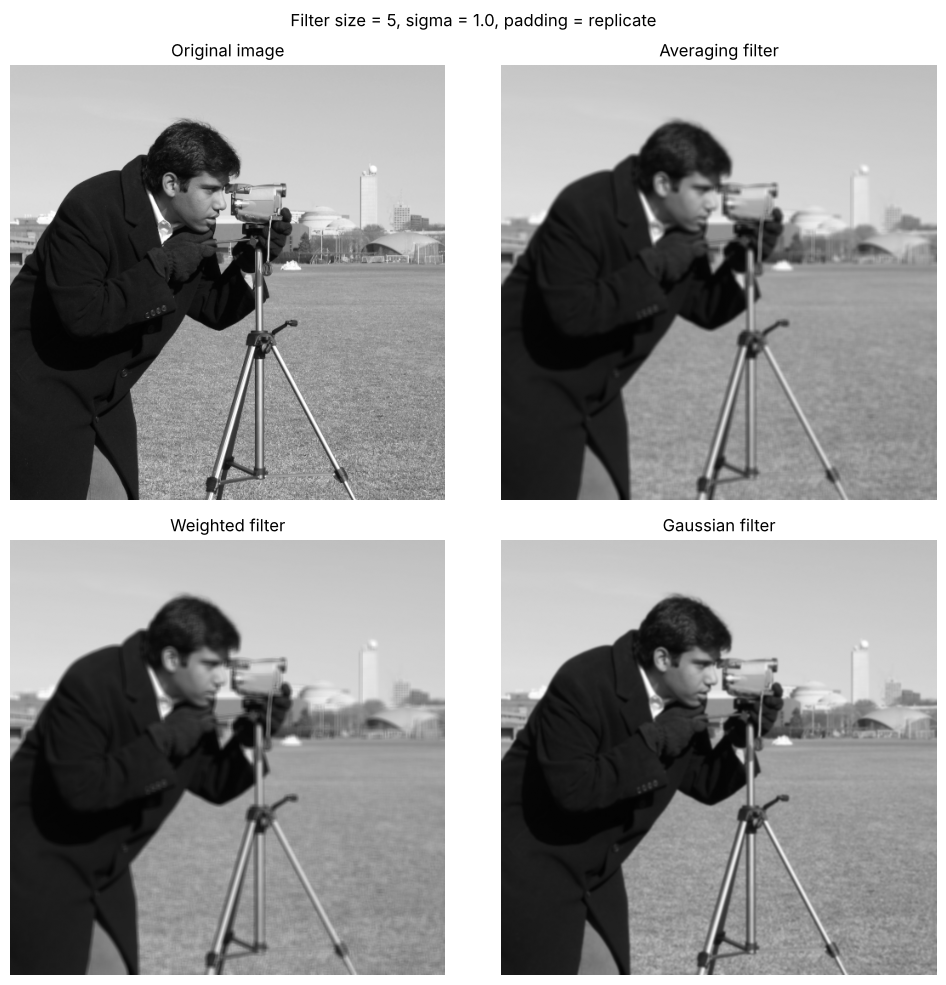

In [5]:
results = {name: apply_filter(image, kernel, padding) for name, kernel in kernels.items()}

panels = {"Original image": image, **results}
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, (title, img) in zip(axes.ravel(), panels.items()):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle(f"Filter size = {filter_size}, sigma = {sigma}, padding = {padding}")
plt.tight_layout()
plt.show()

## Effect of the padding method

The padding method only changes pixels near the image border. To make the effect easy to see, this example uses a large $31 \times 31$ averaging filter and zooms in on the top-left corner.

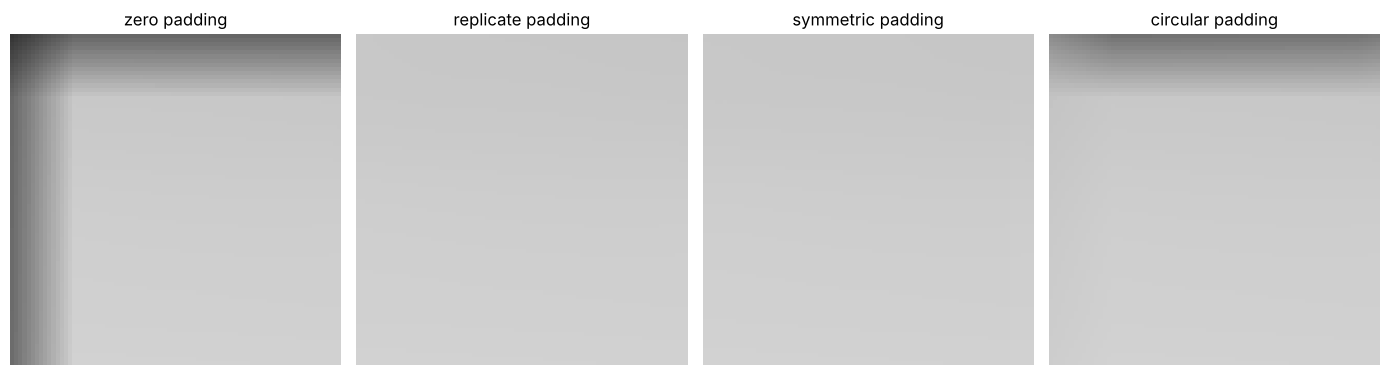

In [6]:
demo_kernel = averaging_kernel(31)
fig, axes = plt.subplots(1, len(PADDING_MODES), figsize=(14, 4))
for ax, name in zip(axes, PADDING_MODES):
    ax.imshow(apply_filter(image, demo_kernel, name)[:80, :80], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name} padding")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Conclusion

- All three filters reduce fine detail, and the effect grows with the filter size.
- The **averaging filter** weights all neighbours equally, which gives a uniform blur.
- The **weighted filter** $\max(|x|,|y|)$ weights distant pixels most and ignores the centre pixel, so it blurs strongly for its size.
- The **Gaussian filter** weights nearby pixels most, and a larger sigma gives more blur.
- **Zero padding** darkens the borders. **Replicate** and **symmetric** padding avoid this. **Circular padding** brings in pixels from the opposite side of the image, so the border can change if the two sides differ, as at the top of the sample image.